# Exploratory Data Analysis & Data Profiling
Initial data exploration and profiling of the e-commerce transaction dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## 1. Load Raw Dataset

In [2]:
df_raw = pd.read_csv('../data/raw/Pakistan Largest Ecommerce Dataset.csv', low_memory=False)
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (1048575, 26)


,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,Month,Customer Since,M-Y,FY,Customer ID,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,211131.0,complete,7/1/2016,kreations_YI 06-L,1950.0,1.0,1950.0,100147443,Women's Fashion,\N,...,7.0,2016-7,7-2016,FY17,1.0,NaN,NaN,NaN,NaN,NaN
1,211133.0,canceled,7/1/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1.0,240.0,100147444,Beauty & Grooming,\N,...,7.0,2016-7,7-2016,FY17,2.0,NaN,NaN,NaN,NaN,NaN
2,211134.0,canceled,7/1/2016,Ego_UP0017-999-MR0,2450.0,1.0,2450.0,100147445,Women's Fashion,\N,...,7.0,2016-7,7-2016,FY17,3.0,NaN,NaN,NaN,NaN,NaN
3,211135.0,complete,7/1/2016,kcc_krone deal,360.0,1.0,60.0,100147446,Beauty & Grooming,R-FSD-52352,...,7.0,2016-7,7-2016,FY17,4.0,NaN,NaN,NaN,NaN,NaN
4,211136.0,order_refunded,7/1/2016,BK7010400AG,555.0,2.0,1110.0,100147447,Soghaat,\N,...,7.0,2016-7,7-2016,FY17,5.0,NaN,NaN,NaN,NaN,NaN


## 2. Check and Remove Empty Rows
The file contains blank rows at the end due to Excel row limits. Let's filter them out.

In [3]:
empty_rows = df_raw.isnull().all(axis=1).sum()
print("Total rows:", len(df_raw))
print("Empty rows:", empty_rows)
print("Valid rows:", len(df_raw) - empty_rows)

df = df_raw.dropna(how='all').copy()
print("Shape after dropping empty rows:", df.shape)

Total rows: 1048575
Empty rows: 464051
Valid rows: 584524


Shape after dropping empty rows: (584524, 26)


## 3. Drop Unnamed Trailing Columns

In [4]:
unnamed = [c for c in df.columns if 'Unnamed' in c]
print("Dropping unnamed columns:", unnamed)
df = df.drop(columns=unnamed)
print("Remaining columns:", df.shape[1])

Dropping unnamed columns: ['Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']
Remaining columns: 21


## 4. Check Missing Values in Columns

In [5]:
df.isnull().sum()

item_id                       0
status                       15
created_at                    0
sku                          20
price                         0
qty_ordered                   0
grand_total                   0
increment_id                  0
category_name_1             164
sales_commission_code    137178
discount_amount               0
payment_method                0
Working Date                  0
BI Status                     0
 MV                           0
Year                          0
Month                         0
Customer Since               11
M-Y                           0
FY                            0
Customer ID                  11
dtype: int64

## 5. Check Granularity and Order Duplication Bug
Checking line items count vs distinct orders count.

In [6]:
print("Total line items:", len(df))
print("Unique orders:", df['increment_id'].nunique())
print("Unique items:", df['item_id'].nunique())

order_counts = df['increment_id'].value_counts()
print("Single-item orders:", (order_counts == 1).sum())
print("Multi-item orders:", (order_counts > 1).sum())

Total line items: 584524
Unique orders: 408782
Unique items: 584524


Single-item orders:

 326928
Multi-item orders: 81854


Notice that grand_total is repeated on every line item of a multi-item order:

In [7]:
df[df['increment_id'] == '100163351'][['increment_id', 'sku', 'qty_ordered', 'price', 'discount_amount', 'grand_total']]

,increment_id,sku,qty_ordered,price,discount_amount,grand_total
18822,100163351,Zuk Z1-Grey-Karachi,1.0,24999.0,0.0,24999.0


Checking the total revenue overstatement caused by summing repeated grand_total:

In [8]:
raw_total = df['grand_total'].sum()
order_total = df.drop_duplicates('increment_id')['grand_total'].sum()
print("Raw sum of grand_total:", raw_total)
print("Distinct order total:", order_total)
print("Discrepancy (overstatement):", raw_total - order_total)

Raw sum of grand_total: 4986351289.5665
Distinct order total: 3896425480.846
Discrepancy (overstatement): 1089925808.7204995


## 6. Order Status Distribution

In [9]:
df['status'] = df['status'].astype(str).str.lower().str.strip()

def get_status_group(s):
    if s in ['complete', 'paid', 'closed', 'received']:
        return 'Completed'
    elif s in ['canceled', 'order_refunded']:
        return 'Canceled'
    elif s in ['refund', 'exchange']:
        return 'Refunded'
    else:
        return 'Pending / Other'

df['status_group'] = df['status'].apply(get_status_group)
status_counts = df.drop_duplicates('increment_id')['status_group'].value_counts()
print(status_counts)

status_group
Completed          205934
Canceled           197723
Refunded             4095
Pending / Other      1030
Name: count, dtype: int64


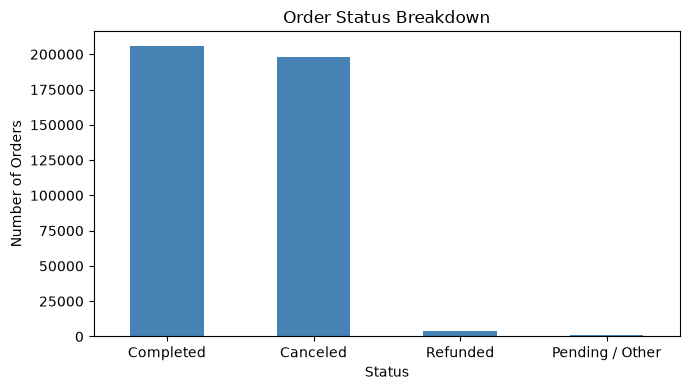

In [10]:
plt.figure(figsize=(7, 4))
status_counts.plot(kind='bar', color='steelblue')
plt.title('Order Status Breakdown')
plt.xlabel('Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Fulfillment by Payment Method

In [11]:
orders_df = df.drop_duplicates('increment_id')
top_pm = orders_df['payment_method'].value_counts().head(6).index
pm_table = pd.crosstab(orders_df[orders_df['payment_method'].isin(top_pm)]['payment_method'], orders_df['status_group'], normalize='index') * 100
pm_table.round(1)

status_group,Canceled,Completed,Pending / Other,Refunded
payment_method,,,,
Easypay,68.3,31.3,0.0,0.4
Payaxis,70.4,29.2,0.0,0.4
bankalfalah,76.5,22.9,0.3,0.2
cod,29.9,67.9,0.5,1.7
easypay_voucher,39.7,59.9,0.1,0.3
jazzwallet,56.2,43.0,0.0,0.7


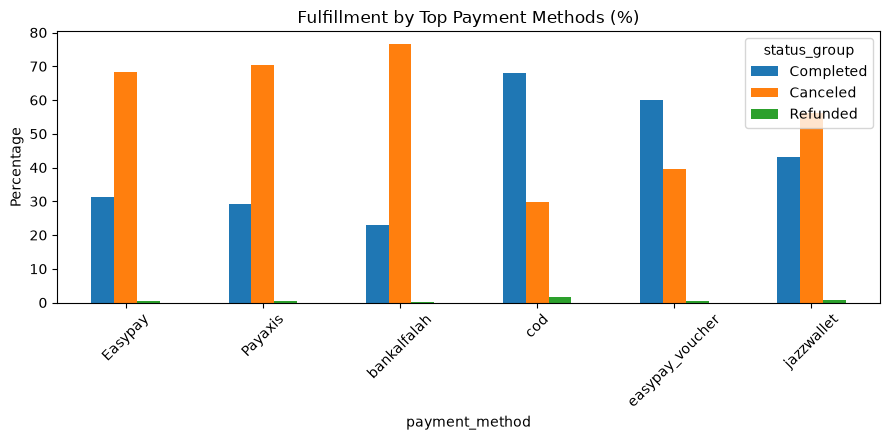

In [12]:
pm_table[['Completed', 'Canceled', 'Refunded']].plot(kind='bar', figsize=(9, 4.5))
plt.title('Fulfillment by Top Payment Methods (%)')
plt.ylabel('Percentage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Monthly Order Trend

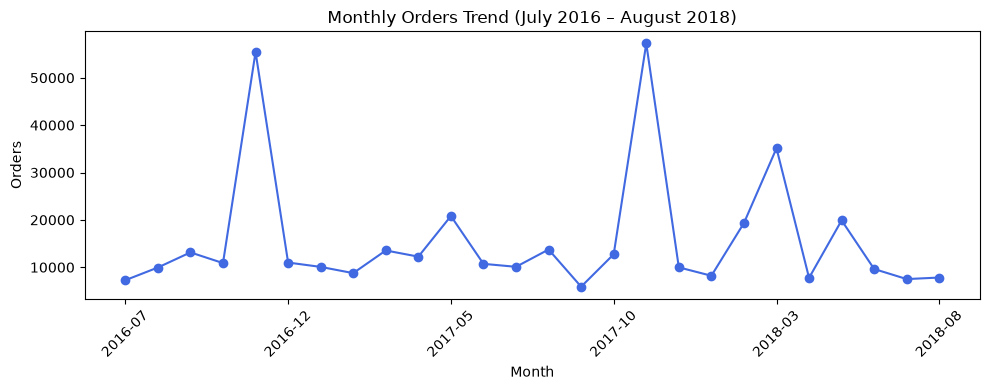

In [13]:
df['order_date'] = pd.to_datetime(df['created_at'], errors='coerce')
df['order_month'] = df['order_date'].dt.to_period('M').astype(str)

monthly_orders = df.groupby('order_month')['increment_id'].nunique()

plt.figure(figsize=(10, 4))
monthly_orders.plot(kind='line', marker='o', color='royalblue')
plt.title('Monthly Orders Trend (July 2016 – August 2018)')
plt.xlabel('Month')
plt.ylabel('Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Top Product Categories

In [14]:
df['category'] = df['category_name_1'].replace({r'\N': 'Unknown', '\\N': 'Unknown'}).fillna('Unknown').str.strip()
cat_counts = df['category'].value_counts().head(10)
cat_counts

category
Mobiles & Tablets    115710
Men's Fashion         92221
Women's Fashion       59721
Appliances            52413
Superstore            43613
Beauty & Grooming     41496
Soghaat               34011
Others                29218
Home & Living         26504
Entertainment         26326
Name: count, dtype: int64

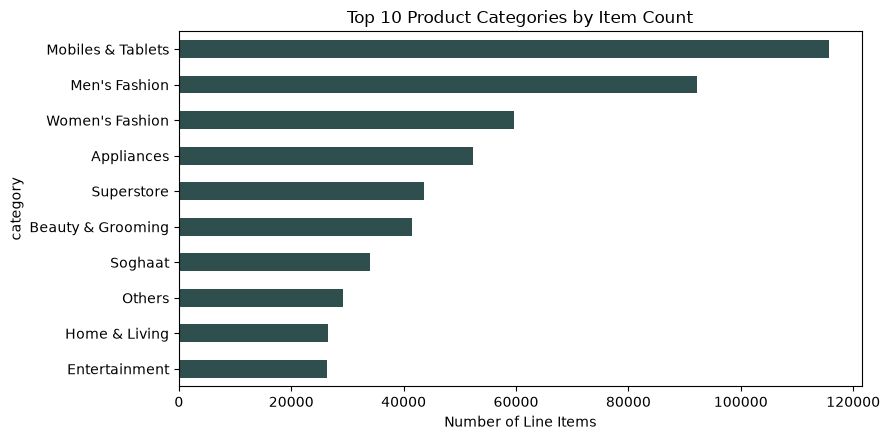

In [15]:
plt.figure(figsize=(9, 4.5))
cat_counts.plot(kind='barh', color='darkslategray')
plt.title('Top 10 Product Categories by Item Count')
plt.xlabel('Number of Line Items')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Customer Repeat Rate

In [16]:
cust_counts = df.dropna(subset=['Customer ID']).groupby('Customer ID')['increment_id'].nunique()
repeat_rate = (cust_counts > 1).mean() * 100
print("Total customers:", len(cust_counts))
print("Repeat customers (2+ orders):", (cust_counts > 1).sum())
print(f"Repeat Purchase Rate: {repeat_rate:.1f}%")

Total customers: 115326
Repeat customers (2+ orders): 53086
Repeat Purchase Rate: 46.0%
